<a href="https://colab.research.google.com/github/kenwkliu/ideas/blob/master/colab/LLM_Sentiment_Investment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#@title Using Google cobal free LLM models
!pip install -q feedparser # for reading RSS feed

import json
import yfinance as yf
import numpy as np
import pandas as pd
import urllib.parse, feedparser
import matplotlib.pyplot as plt
from datetime import date, timedelta
from typing import List, Tuple, Optional


def get_recent_quarters(num_quarters: int, today: Optional[date] = None) -> List[Tuple[str, str]]:
    """
    Return the most recent `num_quarters` full (completed) calendar quarters
    as (start_date, end_date) tuples in YYYY-MM-DD format, oldest first.
    """
    if num_quarters <= 0:
        return []

    today = today or date.today()

    # Start of the current quarter (first day of the quarter containing today)
    current_q_index = (today.month - 1) // 3          # 0..3
    year = today.year
    quarter = current_q_index                          # current quarter (0-based)

    result = []
    for _ in range(num_quarters):
        # Step back one quarter
        quarter -= 1
        if quarter < 0:
            quarter = 3
            year -= 1

        start_month = quarter * 3 + 1
        start = date(year, start_month, 1)

        # End = day before the first day of the next quarter
        if quarter == 3:
            next_start = date(year + 1, 1, 1)
        else:
            next_start = date(year, start_month + 3, 1)
        end = next_start - timedelta(days=1)

        result.append((start.strftime(DATE_FORMAT), end.strftime(DATE_FORMAT)))

    result.reverse()  # oldest first
    return result


def get_previous_quarter_range(quarter):
    """
    Given a quarter (pd.Period or string like '2026Q1'),
    return (start_date, end_date) of the previous quarter as 'YYYY-MM-DD'.
    """
    q = pd.Period(quarter, freq="Q")
    prev_q = q - 1
    start = prev_q.start_time.strftime("%Y-%m-%d")
    end = prev_q.end_time.strftime("%Y-%m-%d")
    return start, end


def normalize_scores(scores):
    """Convert four scores in [-1, 1] into values summing to 1.00."""
    if len(scores) != 4:
        raise ValueError("Expected exactly four scores.")
    if any(not -1 <= score <= 1 for score in scores):
        raise ValueError("Each score must be between -1 and 1.")

    values = [score + 1 for score in scores]
    total = sum(values)

    if total == 0:  # All scores are -1; assign equal values.
        return [0.25, 0.25, 0.25, 0.25]

    result = [round(value / total, 2) for value in values[:3]]
    result.append(round(1.00 - sum(result), 2))
    return result


def llm_analysis(current_quarter):
  startDate, endDate = get_previous_quarter_range(current_quarter)

  quarter_llm = []
  quarter_scores = []

  for news_query in ticker_list:
    # Specify the RSS feed URL
    feed_url = f"https://news.google.com/rss/search?q={urllib.parse.quote(news_query)}+after:{startDate}+before:{endDate}"

    # Parse the RSS feed
    feed = feedparser.parse(feed_url)

    # Extract headlines and other relevant information
    entries = feed.entries
    all_headlines = ''

    # Combine all the news headiines
    for entry in entries:
        all_headlines += entry.title + " "

    questionWithContext = 'Return a sentiment score, sentiment reasoning, news summary in this format strictly - {"score":num(-1 to 1), "reason":"text", "summary":"text"}. Here are the news: \n\n' + all_headlines
    result = ai.generate_text(questionWithContext, model_name=ai_model)
    llm_output = json.loads(result)
    llm_output['name'] = news_query

    quarter_scores.append(llm_output["score"])
    quarter_llm.append(llm_output)

  df_quarter = pd.DataFrame(quarter_llm).set_index("name")
  quarter_weights = normalize_scores(quarter_scores)

  print(f"Based on the news from {startDate} to {endDate}")
  print(f"Sentiment scores: {quarter_scores}")
  print(f"{current_quarter} Quarter rebalance: {quarter_weights}")

  return df_quarter, quarter_weights


# ---------------- PnL Metrics ----------------
def max_drawdown(v):
    dd = v / v.cummax() - 1
    return dd.min(), dd

def sharpe(v):
    r = v.pct_change().dropna()
    if len(r) < 2 or r.std() == 0:
        return np.nan
    excess = r - rf_annual / trading_days
    return excess.mean() / r.std() * np.sqrt(trading_days)

def metrics(v, start_value=None):
    sv = v.iloc[0] if start_value is None else start_value
    ret = v.iloc[-1] / sv - 1
    mdd, _ = max_drawdown(v)
    return {"Start Value": sv, "End Value": v.iloc[-1],
            "Return %": ret * 100, "Max Drawdown %": mdd * 100,
            "Sharpe": sharpe(v)}


pd.options.display.float_format = '{:.2f}'.format
DATE_FORMAT = '%Y-%m-%d'

# Enable Google interactive table
from google.colab import data_table
data_table.enable_dataframe_formatter()

# Use the Google colab free AI models
from google.colab import ai
ai_model = next(model for model in ai.list_models() if "lite" in model)

In [2]:
investment_theme = 'Global_Index' # @param["Global_Index", "HK_Tech", "US_Tech"] {allow-input: false}
capital = 1_000_000
rf_annual = 0.03

portfolio_tickers = {}

portfolio_tickers['Global_Index'] = {
    "Hang Seng Index": "^HSI",
    "Nikkei 225": "^N225",
    "Dow Jones index":  "^DJI",
    "FTSE 100": "^FTSE",
}

portfolio_tickers['HK_Tech'] = {
    "Alibaba": "9988.HK",
    "Tencent": "0700.HK",
    "Meituan": "3690.HK",
    "Xiaomi":  "1810.HK",
}

portfolio_tickers['US_Tech'] = {
    "Apple": "AAPL",
    "nVidia": "NVDA",
    "Google": "GOOGL",
    "Microsoft":  "MSFT",
}


tickers = portfolio_tickers[investment_theme]
ticker_list = list(tickers) # risk-free rate



In [3]:
quarters = get_recent_quarters(4)
start, end = quarters[0][0], quarters[len(quarters)-1][1]

# yfinance's end date is exclusive, so add one day
end_incl = (pd.Timestamp(end) + pd.Timedelta(days=1)).strftime(DATE_FORMAT)
raw = yf.download(list(tickers.values()), start=start, end=end_incl,
                  auto_adjust=True, progress=False)["Close"]

raw = raw[list(tickers.values())].dropna(how="all").ffill().dropna()
raw.columns = list(tickers.keys())
trading_days = len(raw)

print(f"Data range: {raw.index[0].date()} -> {raw.index[-1].date()}  ({trading_days} days)")
raw

Data range: 2025-10-02 -> 2026-09-30  (259 days)


,Hang Seng Index,Nikkei 225,Dow Jones index,FTSE 100
Date,,,,
2025-10-02,27287.12,44936.73,46519.72,9427.70
2025-10-03,27140.92,45769.50,46758.28,9491.30
2025-10-06,26957.77,47944.76,46694.97,9479.10
2025-10-07,26957.77,47950.88,46602.98,9483.60
2025-10-08,26829.46,47734.99,46601.78,9548.90
...,...,...,...,...
2026-09-24,24761.13,65513.99,51349.98,10680.00
2026-09-25,24510.09,66364.20,51828.62,10695.30
2026-09-28,24642.51,65877.62,51481.51,10684.90


In [4]:
# ---------------- Portfolio (equal weight, buy & hold) ----------------
alloc = capital / len(tickers)
shares = alloc / raw.iloc[0]               # buy on first day, fractional shares
position_values = raw * shares
portfolio = position_values.sum(axis=1)
portfolio.name = "Portfolio"

# ---------------- Quarterly metrics ----------------
# Quarters: calendar quarters (Q4 2025, Q1 2026, Q2 2026, Q3 2026)
quarter_list = []
weights = {}
rows = []
prev_end_val = None

for q, grp in portfolio.groupby(portfolio.index.to_period("Q")):
    # Start from previous quarter's closing value so returns chain correctly
    seg = grp if prev_end_val is None else pd.concat(
        [pd.Series([prev_end_val], index=[grp.index[0] - pd.Timedelta(days=1)]), grp])
    m = metrics(seg)
    quarter_list.append(str(q))
    m["Quarter"] = str(q)
    rows.append(m)
    prev_end_val = grp.iloc[-1]


overall = pd.Series(metrics(portfolio), name="Overall")
print(overall)

quarterly = pd.DataFrame(rows).set_index("Quarter")
quarterly

Start Value      1000000.00
End Value        1151696.90
Return %              15.17
Max Drawdown %        -9.19
Sharpe                 0.97
Name: Overall, dtype: float64


,Start Value,End Value,Return %,Max Drawdown %,Sharpe
Quarter,,,,,
2025Q4,1000000.00,1036532.40,3.65,-4.73,1.11
2026Q1,1036532.40,1030090.21,-0.62,-9.19,-0.34
2026Q2,1030090.21,1158939.89,12.51,-3.52,3.09
2026Q3,1158939.89,1151696.90,-0.62,-4.04,-0.52


In [5]:
current_quarter = quarter_list[0]
df_quarter, quarter_weight = llm_analysis(current_quarter)
weights[current_quarter] = quarter_weight

df_quarter

Based on the news from 2025-07-01 to 2025-09-30
Sentiment scores: [0.35, 0.8, 0.2, 0.65]
2025Q4 Quarter rebalance: [0.23, 0.3, 0.2, 0.27]


,score,reason,summary
name,,,
Hang Seng Index,0.35,The news reflects a generally positive yet vol...,Hong Kong and Chinese stock markets experience...
Nikkei 225,0.80,The news highlights a strong bullish trend in ...,"Japan's Nikkei 225 index reached record highs,..."
Dow Jones index,0.20,The news mix includes positive milestones like...,The stock market saw fading gains with the Dow...
FTSE 100,0.65,The news reflects a generally positive market ...,The UK's FTSE 100 index has reached historic m...


In [6]:
current_quarter = quarter_list[1]
df_quarter, quarter_weight = llm_analysis(current_quarter)
weights[current_quarter] = quarter_weight

df_quarter

Based on the news from 2025-10-01 to 2025-12-31
Sentiment scores: [0.6, 0.6, 0.2, 0.6]
2026Q1 Quarter rebalance: [0.27, 0.27, 0.2, 0.26]


,score,reason,summary
name,,,
Hang Seng Index,0.60,The news reflects a generally positive sentime...,Asian markets displayed mixed trading near yea...
Nikkei 225,0.60,"The news is predominantly positive, driven by ...",Japan's Nikkei 225 index shattered historic mi...
Dow Jones index,0.20,The news mix includes positive milestones like...,"The Dow Jones recently hit the 48,000 mileston..."
FTSE 100,0.60,The news coverage heavily highlights the FTSE ...,"The UK's FTSE 100 wrapped up a stellar year, h..."


In [7]:
current_quarter = quarter_list[2]
df_quarter, quarter_weight = llm_analysis(current_quarter)
weights[current_quarter] = quarter_weight

df_quarter

Based on the news from 2026-01-01 to 2026-03-31
Sentiment scores: [-0.3, 0.15, 0.2, 0.7]
2026Q2 Quarter rebalance: [0.15, 0.24, 0.25, 0.36]


,score,reason,summary
name,,,
Hang Seng Index,-0.30,The news reflects high volatility and mixed-to...,Asian markets experienced significant volatili...
Nikkei 225,0.15,The news reflects a mixed to moderately positi...,Japanese stocks surged to record highs followi...
Dow Jones index,0.20,The news headlines present a mixed picture cen...,The Dow Jones Industrial Average reached a his...
FTSE 100,0.70,The news coverage largely highlights the UK's ...,Britain's FTSE 100 experienced a strong start ...


In [8]:
current_quarter = quarter_list[3]
df_quarter, quarter_weight = llm_analysis(current_quarter)
weights[current_quarter] = quarter_weight

df_quarter

Based on the news from 2026-04-01 to 2026-06-30
Sentiment scores: [-0.35, 0.65, 0.6, -0.2]
2026Q3 Quarter rebalance: [0.14, 0.35, 0.34, 0.17]


,score,reason,summary
name,,,
Hang Seng Index,-0.35,The news flow predominantly highlights negativ...,Hong Kong and Asia-Pacific markets faced persi...
Nikkei 225,0.65,The news reflects a largely positive and bulli...,"Asian markets, led by Japan and South Korea, e..."
Dow Jones index,0.60,Alphabet's debut in the Dow Jones Industrial A...,Alphabet has officially replaced Verizon in th...
FTSE 100,-0.20,The news reflects a mixed-to-negative sentimen...,The UK's FTSE 100 experienced a volatile perio...


In [9]:
# Rebalance at the first trading day's close of each quarter.
# Value is carried over from the previous quarter's last close.
qid = raw.index.to_period("Q")
pv_parts, pos_parts = [], []
value = capital

for i, q in enumerate(qid.unique()):
    key = str(q)                                   # e.g. "2025Q4"
    if key not in weights:
        print(f"No weights for {key}, skipped"); continue
    p = raw[qid == q]
    ref = raw.iloc[0] if i == 0 else raw[qid < q].iloc[-1]
    shares = value * np.array(weights[key]) / ref
    pos = p * shares
    pv_parts.append(pos.sum(axis=1))
    pos_parts.append(pos)
    value = pv_parts[-1].iloc[-1]

portfolio_rb = pd.concat(pv_parts); portfolio_rb.name = "Rebalanced"
positions_rb = pd.concat(pos_parts)

# ---------------- Quarterly metrics (same chaining logic as the first cell) ----------------
rows, prev_end_val = [], None
for q, grp in portfolio_rb.groupby(portfolio_rb.index.to_period("Q")):
    seg = grp if prev_end_val is None else pd.concat(
        [pd.Series([prev_end_val], index=[grp.index[0] - pd.Timedelta(days=1)]), grp])
    m = metrics(seg); m["Quarter"] = str(q)
    rows.append(m)
    prev_end_val = grp.iloc[-1]

overall_rb = pd.Series(metrics(portfolio_rb), name="Overall (Rebalanced)")
print(overall_rb)

quarterly_rb = pd.DataFrame(rows).set_index("Quarter")
quarterly_rb

Start Value      1000000.00
End Value        1147511.11
Return %              14.75
Max Drawdown %        -9.32
Sharpe                 0.93
Name: Overall (Rebalanced), dtype: float64


,Start Value,End Value,Return %,Max Drawdown %,Sharpe
Quarter,,,,,
2025Q4,1000000.00,1043167.60,4.32,-4.71,1.28
2026Q1,1043167.60,1037182.33,-0.57,-9.32,-0.30
2026Q2,1037182.33,1163036.65,12.13,-3.06,3.26
2026Q3,1163036.65,1147511.11,-1.33,-4.35,-0.76


In [12]:
# ---------------- Comparison with equal-weight buy & hold ----------------
cols = ["Start Value", "End Value", "Return %", "Max Drawdown %", "Sharpe"]
comp = pd.DataFrame({"Equal-Weight": overall, "Rebalanced": overall_rb}).T[cols]
print("\n=== Overall: Equal-Weight vs Rebalanced ===")
print(comp)


=== Overall: Equal-Weight vs Rebalanced ===
              Start Value  End Value  Return %  Max Drawdown %  Sharpe
Equal-Weight   1000000.00 1151696.90     15.17           -9.19    0.97
Rebalanced     1000000.00 1147511.11     14.75           -9.32    0.93


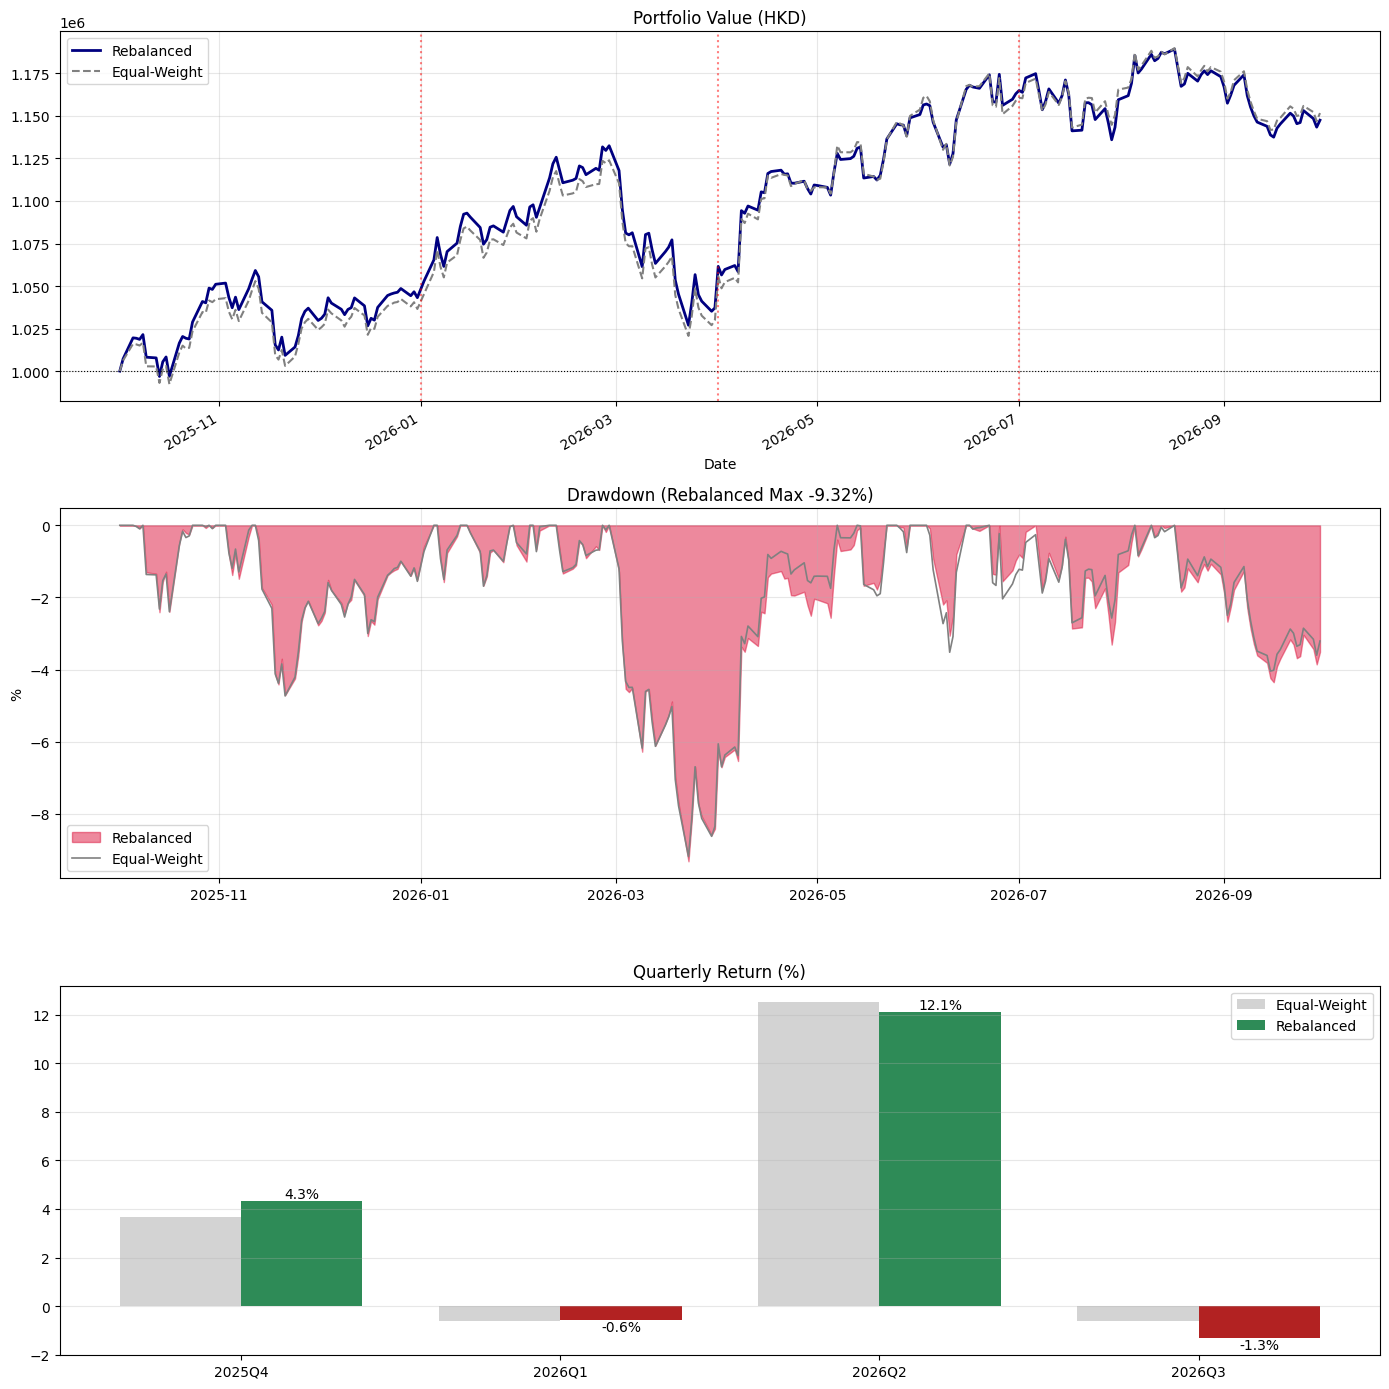

In [13]:
# ---------------- Charts ----------------
_, dd_rb = max_drawdown(portfolio_rb)
_, dd_eq = max_drawdown(portfolio)
edges = [p.start_time for p in portfolio_rb.index.to_period("Q").unique()][1:]

fig, axes = plt.subplots(3, 1, figsize=(14, 14))

# 1) Portfolio Value
ax = axes[0]
portfolio_rb.plot(ax=ax, color="navy", lw=2, label="Rebalanced")
portfolio.plot(ax=ax, color="gray", lw=1.5, ls="--", label="Equal-Weight")
ax.axhline(capital, color="k", lw=.8, ls=":")
for e in edges:
    ax.axvline(e, color="red", ls=":", alpha=.5)
ax.set_title("Portfolio Value (HKD)")
ax.legend()
ax.grid(alpha=.3)

# 2) Drawdown
ax = axes[1]
ax.fill_between(dd_rb.index, dd_rb * 100, 0, color="crimson", alpha=.5, label="Rebalanced")
ax.plot(dd_eq.index, dd_eq * 100, color="gray", lw=1.2, label="Equal-Weight")
ax.set_title(f"Drawdown (Rebalanced Max {dd_rb.min()*100:.2f}%)")
ax.set_ylabel("%")
ax.legend()
ax.grid(alpha=.3)

# 3) Quarterly Return
ax = axes[2]
x = np.arange(len(quarterly_rb))
w = .38
qeq = quarterly.reindex(quarterly_rb.index)
ax.bar(x - w/2, qeq["Return %"], w, color="lightgray", label="Equal-Weight")
ax.bar(x + w/2, quarterly_rb["Return %"], w,
       color=["seagreen" if v >= 0 else "firebrick" for v in quarterly_rb["Return %"]],
       label="Rebalanced")
for i, v in enumerate(quarterly_rb["Return %"]):
    ax.text(i + w/2, v, f"{v:.1f}%", ha="center", va="bottom" if v >= 0 else "top")
ax.set_xticks(x)
ax.set_xticklabels(quarterly_rb.index)
ax.set_title("Quarterly Return (%)")
ax.legend()
ax.grid(alpha=.3, axis="y")

plt.tight_layout()
plt.show()
